In [ ]:
import tensorflow as tf
import tensorflow.keras
from tensorflow.keras.models import Sequential, save_model
from tensorflow.keras.layers import Conv1D, Conv1DTranspose, Dense, BatchNormalization, Activation, Input
from tensorflow.keras.constraints import max_norm
import matplotlib.pyplot as plt
import numpy as np
import math

In [ ]:
#confirm that GPU is used
device_name = tf.test.gpu_device_name()
if device_name != '/device:GPU:0':
    raise SystemError('GPU device not found')
print('Found GPU at: {}'.format(device_name))

Found GPU at: /device:GPU:0


In [ ]:
from google.colab import drive
drive.mount('/content/drive/', force_remount=True)

%cd /content/drive/Shareddrives/Statistics\ and\ Data\ Analysis/Lectures/DL lectures/Lecture 17/Examples/
!ls

Mounted at /content/drive/
/content/drive/My Drive/Didattica/Corsi/AI/Lectures/Lecture3/DenoisingAE
 AE_denoise.ipynb  'Data access.ipynb'	    MC_Methods.ipynb
 data		    Generate_pulses.ipynb


In [ ]:
# Load data
data_noisy = np.load('./data/signal_waves_noisy.npy')
x_val_noisy, y_val_noisy = data_noisy[:,0], data_noisy[:,1]
data_pure = np.load('./data/signal_waves.npy')
x_val_pure, y_val_pure = data_pure[:,0], data_pure[:,1]

In [ ]:
np.shape(x_val_noisy)
test = y_val_noisy[0]

In [ ]:
normalize = True

noisy_input = np.zeros(len(y_val_noisy))
pure_input  = np.zeros(len(y_val_noisy))
scale_factors = np.ones(len(y_val_noisy))

#rescale the pulse shape to take Y values between 0 and 1
if normalize:
    # Reshape data
    y_val_noisy_r = []
    y_val_pure_r = []
    y_scale_factor = []

    for i in range(0, len(y_val_noisy)):
        noisy_sample = y_val_noisy[i]
        pure_sample = y_val_pure[i]

        scale_factor = 1. / np.max(noisy_sample) #compute the scale factor on the noisy ps
        noisy_sample = noisy_sample * scale_factor
        pure_sample  = pure_sample  * scale_factor

        y_val_noisy_r.append(noisy_sample)
        y_val_pure_r.append(pure_sample)
        y_scale_factor.append(scale_factor)

    noisy_input   = np.array(y_val_noisy_r)
    pure_input    = np.array(y_val_pure_r)
    scale_factors = np.array(y_scale_factor)


# Use the shapes as they are. No normalization.
else:
    noisy_input   = np.array(y_val_noisy)
    pure_input    = np.array(y_val_pure)

In [ ]:
input_shape = 600 # The input shape for a single pulse waveform
batch_size = 128
no_epochs = 50
train_test_split = 0.2
validation_split = 0.2
verbosity = 1

In [ ]:
print(np.shape(noisy_input))
# Train/test split
percentage_training = math.floor((1 - train_test_split) * len(noisy_input))
noisy_input, noisy_input_test = noisy_input[:percentage_training], noisy_input[percentage_training:]
pure_input, pure_input_test = pure_input[:percentage_training], pure_input[percentage_training:]

print(np.shape(noisy_input))

(200000, 600)
(160000, 600)


In [ ]:
import tensorflow as tf
from tensorflow.keras.layers import Dense, Input, BatchNormalization, Activation, Dropout
from tensorflow.keras.models import Model # Imported for potential sub-model summaries if needed
from tensorflow.keras import backend as K

# Define the dimension of the latent space.
latent_dim = 3
beta = 0.01
#beta = 1.5

class VAE(tf.keras.Model):
    """
    Variational Autoencoder (VAE) for denoising pulse shapes.
    The VAE encodes noisy input into a latent distribution, samples from it
    using the reparameterization trick, and then decodes to reconstruct
    the pure signal. This class inherits from tf.keras.Model to allow for
    custom training and test steps to handle the VAE's specific loss components.
    """
    def __init__(self, original_dim, latent_dim, **kwargs):
        super(VAE, self).__init__(**kwargs)
        self.original_dim = original_dim
        self.latent_dim = latent_dim

        # --- Encoder Network Layers ---
        # The encoder takes the noisy input and maps it to the parameters
        # (mean and log-variance) of the latent distribution.
        self.enc_dense1 = Dense(256, name='encoder_dense_1')
        self.enc_bn1 = BatchNormalization(name='encoder_bn_1')
        self.enc_act1 = Activation('relu', name='encoder_activation_1')
        self.enc_dropout1 = Dropout(0.2, name='encoder_dropout_1') # Added dropout

        self.enc_dense2 = Dense(128, name='encoder_dense_2')
        self.enc_bn2 = BatchNormalization(name='encoder_bn_2')
        self.enc_act2 = Activation('relu', name='encoder_activation_2')
        self.enc_dropout2 = Dropout(0.2, name='encoder_dropout_2') # Added dropout

        self.enc_dense3 = Dense(64, name='encoder_dense_3') # Increased complexity
        self.enc_bn3 = BatchNormalization(name='encoder_bn_3')
        self.enc_act3 = Activation('relu', name='encoder_activation_3')
        self.enc_dropout3 = Dropout(0.2, name='encoder_dropout_3') # Added dropout

        self.enc_dense4 = Dense(32, name='encoder_dense_4') # New layer
        self.enc_bn4 = BatchNormalization(name='encoder_bn_4')
        self.enc_act4 = Activation('relu', name='encoder_activation_4')

        # Output layers for the mean (mu) and log-variance (log_sigma^2) of the latent space
        self.z_mean_dense = Dense(latent_dim, name='z_mean_output')
        self.z_log_var_dense = Dense(latent_dim, name='z_log_var_output')

        # --- Decoder Network Layers ---
        # The decoder takes a sample from the latent space and reconstructs
        # the original pure signal.
        self.dec_dense1 = Dense(32, name='decoder_dense_1')
        self.dec_bn1 = BatchNormalization(name='decoder_bn_1')
        self.dec_act1 = Activation('relu', name='decoder_activation_1')
        self.dec_dropout1 = Dropout(0.2, name='decoder_dropout_1') # Added dropout

        self.dec_dense2 = Dense(64, name='decoder_dense_2') # Increased complexity
        self.dec_bn2 = BatchNormalization(name='decoder_bn_2')
        self.dec_act2 = Activation('relu', name='decoder_activation_2')
        self.dec_dropout2 = Dropout(0.2, name='decoder_dropout_2') # Added dropout

        self.dec_dense3 = Dense(128, name='decoder_dense_3')
        self.dec_bn3 = BatchNormalization(name='decoder_bn_3')
        self.dec_act3 = Activation('relu', name='decoder_activation_3')
        self.dec_dropout3 = Dropout(0.2, name='decoder_dropout_3') # Added dropout

        self.dec_dense4 = Dense(256, name='decoder_dense_4') # New layer
        self.dec_bn4 = BatchNormalization(name='decoder_bn_4')
        self.dec_act4 = Activation('relu', name='decoder_activation_4')

        # Final layer to reconstruct the original signal shape (e.g., 600 dimensions)
        self.dec_output = Dense(original_dim, activation='linear', name='decoder_output')

    # Explicitly implement the build method for the VAE Model subclass.
    # This ensures all internal layers are built when model.build() is called.
    def build(self, input_shape):
        # Create a dummy input for the encoder path to trigger building of its layers.
        # The input_shape for the VAE is (batch_size, original_dim).
        # We use a batch size of 1 for the dummy input.
        dummy_encoder_input = tf.zeros(shape=(1, self.original_dim))
        # Pass the dummy input through the encoder path to build its layers.
        self.encode(dummy_encoder_input)

        # Create a dummy input for the decoder path to trigger building of its layers.
        # The input to the decoder is a latent space sample, so its shape is (batch_size, latent_dim).
        dummy_decoder_input = tf.zeros(shape=(1, self.latent_dim))
        # Pass the dummy input through the decoder path to build its layers.
        self.decode(dummy_decoder_input)

        # Call the base class's build method to finalize the model's build state.
        super().build(input_shape)

    def encode(self, inputs):
        """Encodes the input into the mean and log-variance of the latent space."""
        x = self.enc_dense1(inputs)
        x = self.enc_bn1(x)
        x = self.enc_act1(x)
        x = self.enc_dropout1(x) # Apply dropout

        x = self.enc_dense2(x)
        x = self.enc_bn2(x)
        x = self.enc_act2(x)
        x = self.enc_dropout2(x) # Apply dropout

        x = self.enc_dense3(x)
        x = self.enc_bn3(x)
        x = self.enc_act3(x)
        x = self.enc_dropout3(x) # Apply dropout

        x = self.enc_dense4(x) # New layer
        x = self.enc_bn4(x)
        x = self.enc_act4(x)

        z_mean = self.z_mean_dense(x)
        z_log_var = self.z_log_var_dense(x)
        return z_mean, z_log_var

    def reparameterize(self, z_mean, z_log_var):
        """
        Performs the reparameterization trick to sample from the latent distribution.
        This allows backpropagation through the sampling process.
        z = mu + exp(0.5 * log_var) * epsilon, where epsilon is a standard normal sample.
        """
        batch = K.shape(z_mean)[0]
        dim = K.shape(z_mean)[1]
        epsilon = K.random_normal(shape=(batch, dim)) # Sample from a standard normal distribution
        return z_mean + K.exp(0.5 * z_log_var) * epsilon # Combine for the latent sample

    def decode(self, z):
        """
        Decodes a latent space sample back into the original data space.
        """
        x = self.dec_dense1(z)
        x = self.dec_bn1(x)
        x = self.dec_act1(x)
        x = self.dec_dropout1(x) # Apply dropout

        x = self.dec_dense2(x)
        x = self.dec_bn2(x)
        x = self.dec_act2(x)
        x = self.dec_dropout2(x) # Apply dropout

        x = self.dec_dense3(x)
        x = self.dec_bn3(x)
        x = self.dec_act3(x)
        x = self.dec_dropout3(x) # Apply dropout

        x = self.dec_dense4(x) # New layer
        x = self.dec_bn4(x)
        x = self.dec_act4(x)

        return self.dec_output(x)

    def call(self, inputs):
        """
        Forward pass through the VAE.
        It returns the reconstruction, along with z_mean and z_log_var
        which are needed for the KL divergence loss calculation.
        """
        z_mean, z_log_var = self.encode(inputs)
        z = self.reparameterize(z_mean, z_log_var)
        reconstruction = self.decode(z)
        return reconstruction, z_mean, z_log_var

    def train_step(self, data):
        """
        Custom training step for the VAE. It computes the total VAE loss,
        which is composed of reconstruction loss and KL divergence loss.
        The reconstruction loss is calculated between the VAE's output and the pure signal.
        """
        # Unpack the data: `x_noisy` is the input to the VAE, `x_pure` is the target for reconstruction.
        x_noisy, x_pure = data

        with tf.GradientTape() as tape:
            # Forward pass: get reconstruction, latent mean, and log-variance from noisy input
            reconstruction, z_mean, z_log_var = self(x_noisy)

            # 1. Reconstruction Loss: Mean Squared Error (MSE) between the pure signal and its reconstruction.
            # This term encourages the VAE to accurately reconstruct the underlying pure signal.
            reconstruction_loss = tf.keras.losses.mse(x_pure, reconstruction)
            # Reduce mean over features for each sample, then scale by original dimension
            # This makes the loss less dependent on the input dimension scale and more comparable to sum of squares.
            reconstruction_loss = tf.reduce_mean(reconstruction_loss, axis=-1) * self.original_dim

            # 2. KL Divergence Loss: Measures the difference between the learned latent distribution
            # (parameterized by z_mean and z_log_var) and a standard normal distribution (the prior).
            # This term regularizes the latent space, encouraging it to be continuous and disentangled.
            kl_loss = -0.5 * K.sum(1 + z_log_var - K.square(z_mean) - K.exp(z_log_var), axis=1)

            # Total VAE loss is the sum of reconstruction and KL divergence losses
            total_loss = tf.reduce_mean(reconstruction_loss + beta*kl_loss) # Average loss over the batch

        # Compute gradients and apply optimizer to update model weights
        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))

        # Return a dictionary of metrics to be displayed by model.fit
        return {
            "loss": total_loss,
            "reconstruction_loss": tf.reduce_mean(reconstruction_loss),
            "kl_loss": tf.reduce_mean(kl_loss)
        }

    def test_step(self, data):
        """
        Custom testing (validation) step for the VAE, mirroring the train_step logic.
        """
        x_noisy, x_pure = data
        reconstruction, z_mean, z_log_var = self(x_noisy)

        reconstruction_loss = tf.keras.losses.mse(x_pure, reconstruction)
        reconstruction_loss = tf.reduce_mean(reconstruction_loss, axis=-1) * self.original_dim

        kl_loss = -0.5 * K.sum(1 + z_log_var - K.square(z_mean) - K.exp(z_log_var), axis=1)

        total_loss = tf.reduce_mean(reconstruction_loss + beta*kl_loss)

        return {
            "loss": total_loss,
            "reconstruction_loss": tf.reduce_mean(reconstruction_loss),
            "kl_loss": tf.reduce_mean(kl_loss)
        }

# Instantiate the VAE model
# `input_shape` and `latent_dim` are defined above or in the previous cell.
vae = VAE(original_dim=input_shape, latent_dim=latent_dim)

# Compile the VAE model with an optimizer. The loss is handled by custom train_step.
vae.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4))

# To display the model summary, it needs to be built with a dummy input shape.
# The custom build method in VAE now handles the internal layer building.
vae.build(input_shape=(None, input_shape))
vae.summary()

# Assign the VAE instance to 'model' for compatibility with subsequent cells
model = vae

Model: "vae"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_dense_1 (Dense)         │ (1, 256)               │       153,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_bn_1                    │ (1, 256)               │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_activation_1            │ ?                      │             0 │
│ (Activation)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dropout_1 (Dropout)     │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dense_2 (Dense)         │ (1, 128)               │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_bn_2                    │ (1, 128)               │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_activation_2            │ ?                      │             0 │
│ (Activation)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dropout_2 (Dropout)     │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dense_3 (Dense)         │ (1, 64)                │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_bn_3                    │ (1, 64)                │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_activation_3            │ ?                      │             0 │
│ (Activation)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dropout_3 (Dropout)     │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dense_4 (Dense)         │ (1, 32)                │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_bn_4                    │ (1, 32)                │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_activation_4            │ ?                      │             0 │
│ (Activation)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ z_mean_output (Dense)           │ (1, 3)                 │            99 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ z_log_var_output (Dense)        │ (1, 3)                 │            99 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dense_1 (Dense)         │ (1, 32)                │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_bn_1                    │ (1, 32)                │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_activation_1            │ ?                      │             0 │
│ (Activation)                    │                        │             

 Total params: 398,910 (1.52 MB)

 Trainable params: 396,990 (1.51 MB)

 Non-trainable params: 1,920 (7.50 KB)

In [ ]:
# fit data
history = model.fit(noisy_input, pure_input,
                    epochs=no_epochs,
                    batch_size=batch_size,
                    validation_split=validation_split)

Epoch 1/50
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 15s 6ms/step - kl_loss: 16.1758 - loss: 0.5991 - reconstruction_loss: 0.4374 - val_kl_loss: 16.5357 - val_loss: 0.5622 - val_reconstruction_loss: 0.3968
Epoch 2/50
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - kl_loss: 12.8984 - loss: 0.2780 - reconstruction_loss: 0.1490 - val_kl_loss: 13.4713 - val_loss: 0.2756 - val_reconstruction_loss: 0.1408
Epoch 3/50
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - kl_loss: 12.6182 - loss: 0.2307 - reconstruction_loss: 0.1046 - val_kl_loss: 12.4923 - val_loss: 0.2321 - val_reconstruction_loss: 0.1072
Epoch 4/50
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - kl_loss: 11.7704 - loss: 0.2171 - reconstruction_loss: 0.0993 - val_kl_loss: 12.0897 - val_loss: 0.2068 - val_reconstruction_loss: 0.0859
Epoch 5/50
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - kl_loss: 11.8966 - loss: 0.1958 - reconstruction_loss: 0.0768 - val_kl_loss: 11.8136 - val_loss: 0.1960 - val_reconstruction_loss: 0.0779
Epoch 6/50
1000/1000 ━━━━━━━━

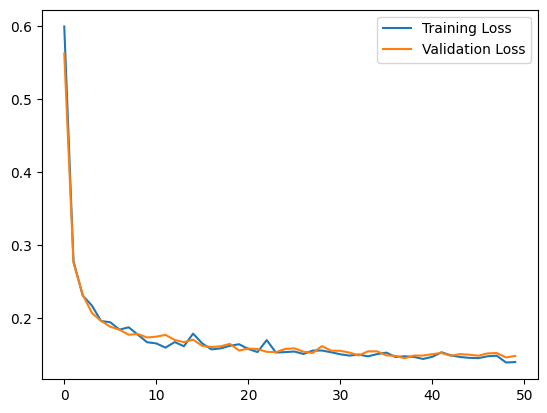

In [ ]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.legend()

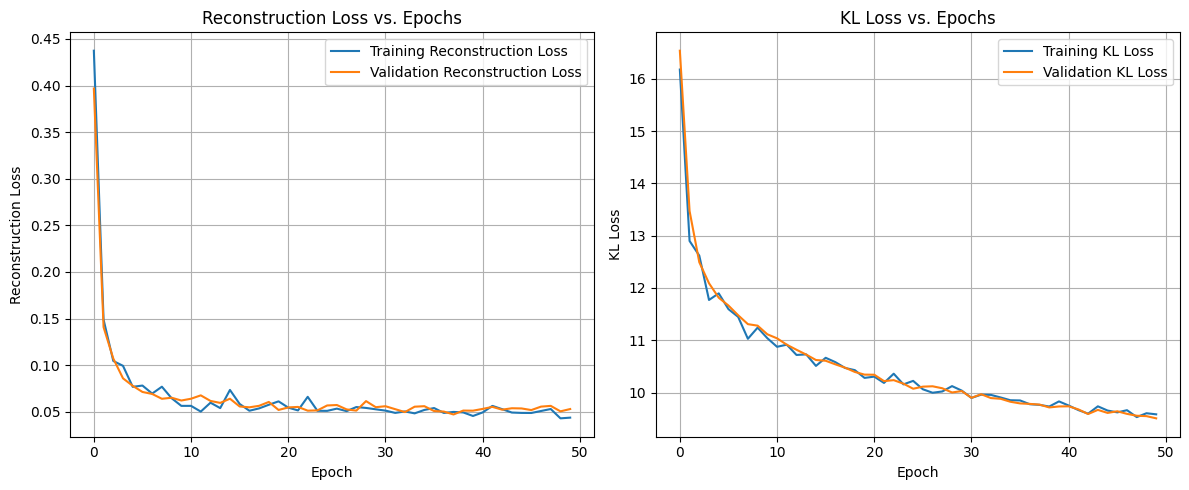

In [ ]:
# Plotting reconstruction_loss and kl_loss

plt.figure(figsize=(12, 5))

# Subplot 1: Reconstruction Loss
plt.subplot(1, 2, 1) # 1 row, 2 columns, first plot
plt.plot(history.history['reconstruction_loss'], label='Training Reconstruction Loss')
plt.plot(history.history['val_reconstruction_loss'], label='Validation Reconstruction Loss')
plt.title('Reconstruction Loss vs. Epochs')
plt.xlabel('Epoch')
plt.ylabel('Reconstruction Loss')
plt.legend()
plt.grid(True)

# Subplot 2: KL Loss
plt.subplot(1, 2, 2) # 1 row, 2 columns, second plot
plt.plot(history.history['kl_loss'], label='Training KL Loss')
plt.plot(history.history['val_kl_loss'], label='Validation KL Loss')
plt.title('KL Loss vs. Epochs')
plt.xlabel('Epoch')
plt.ylabel('KL Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step


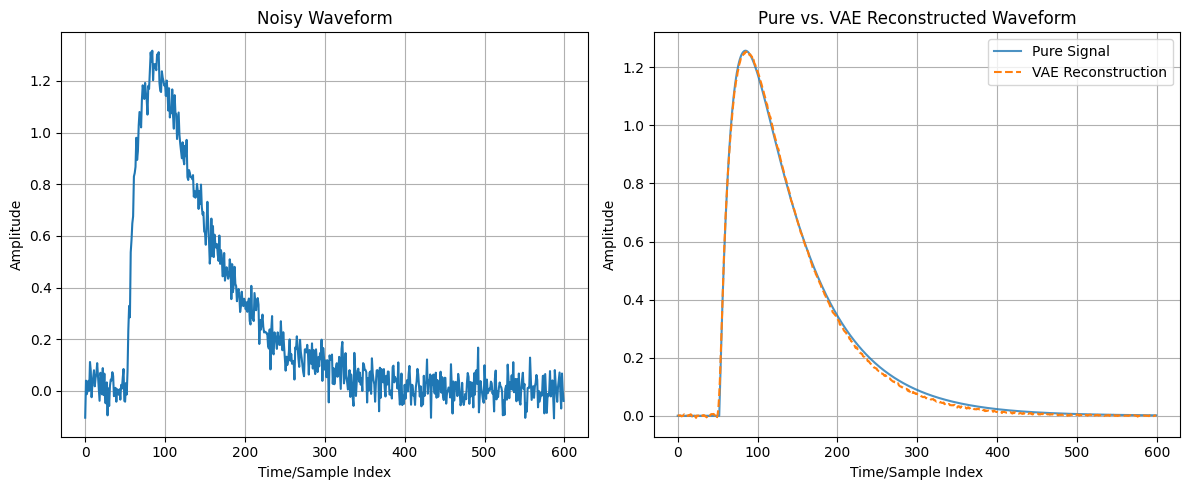

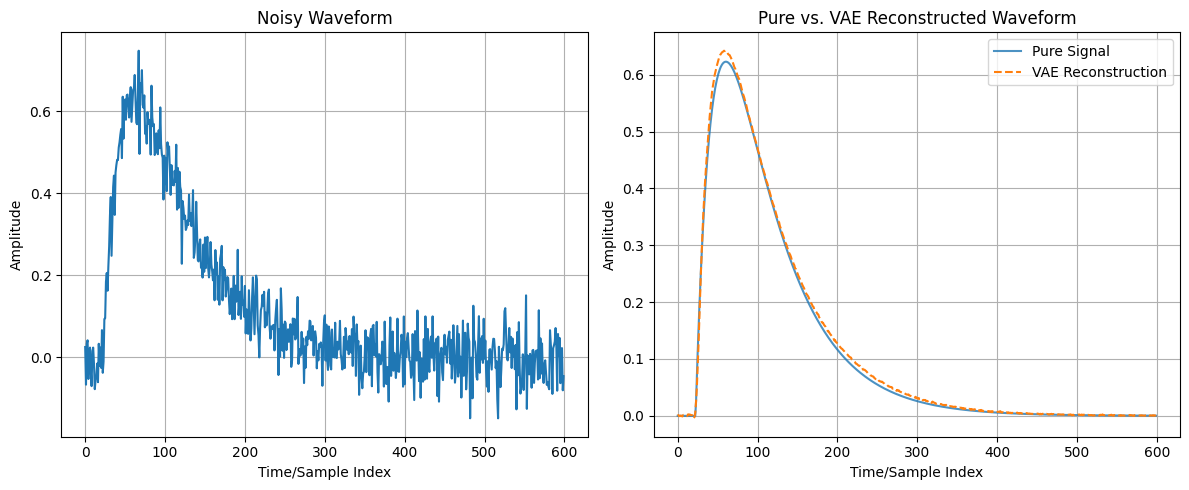

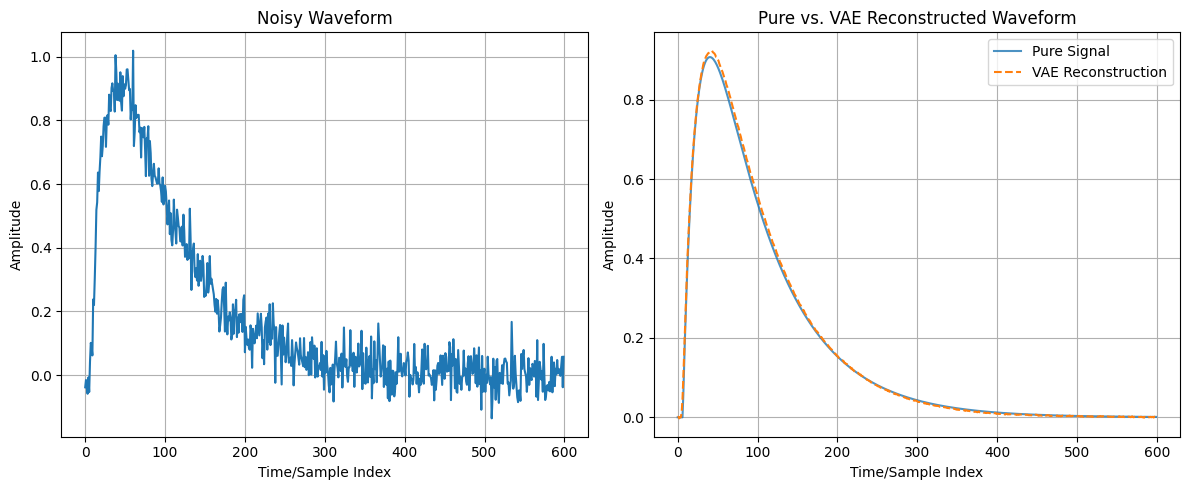

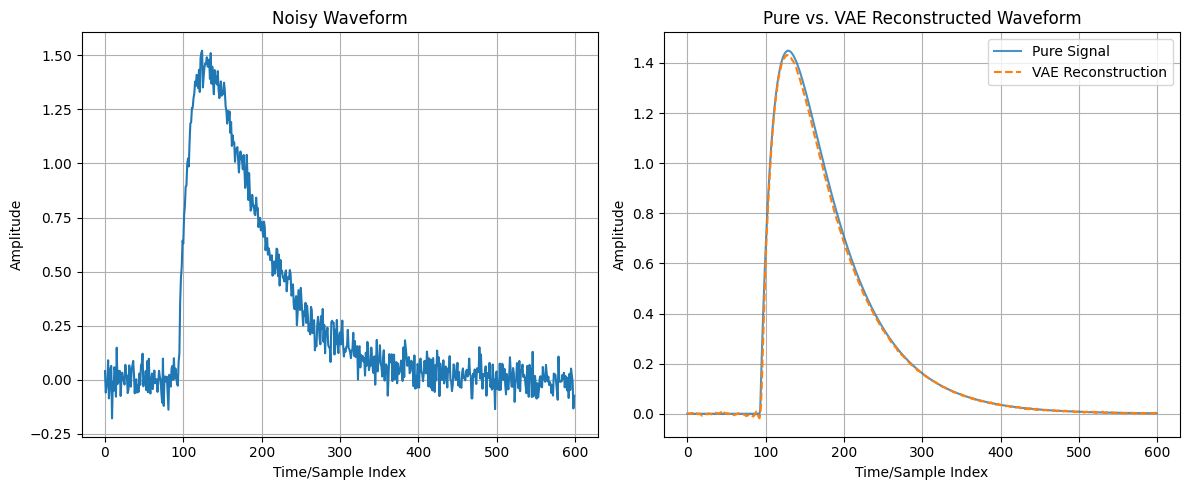

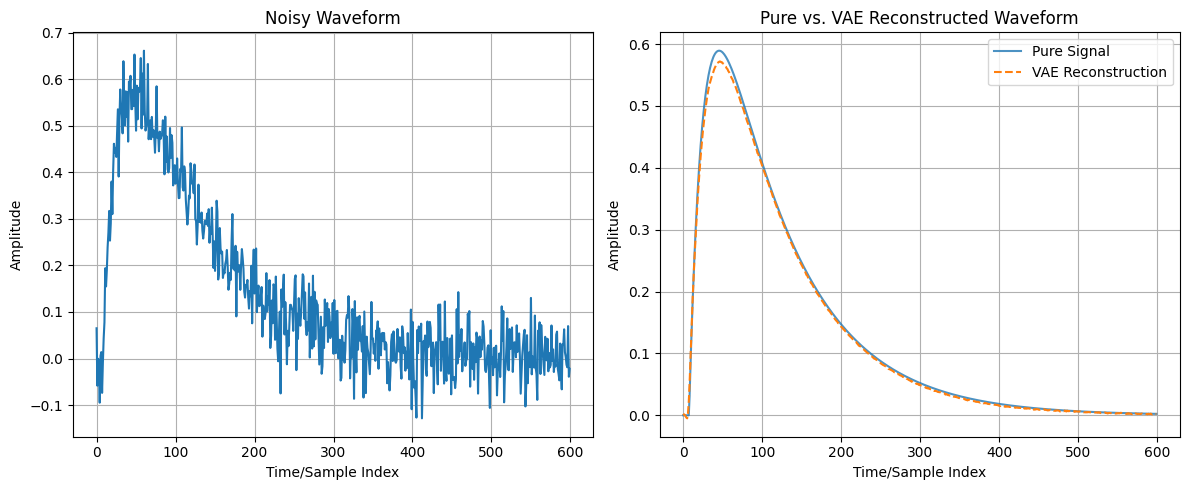

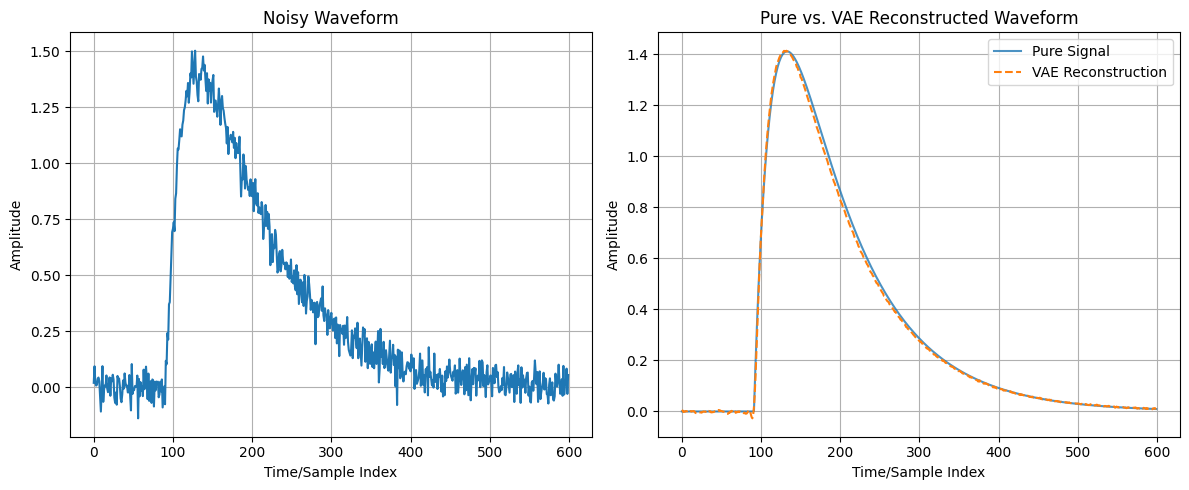

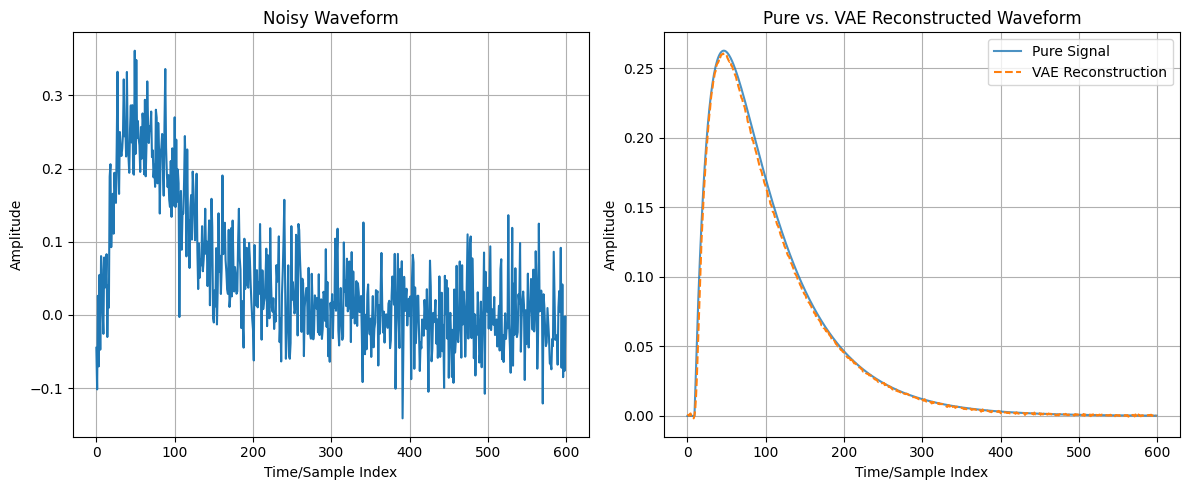

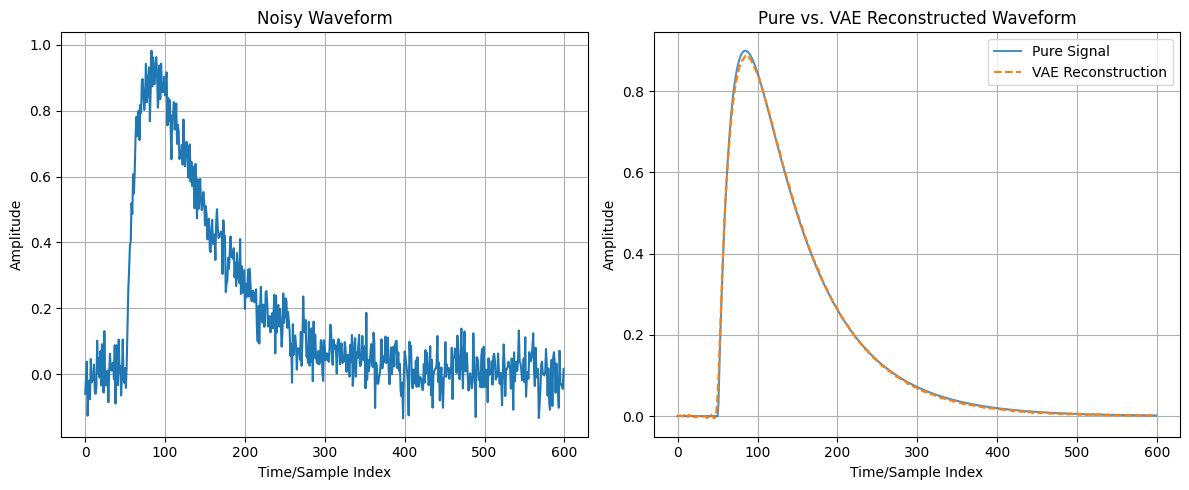

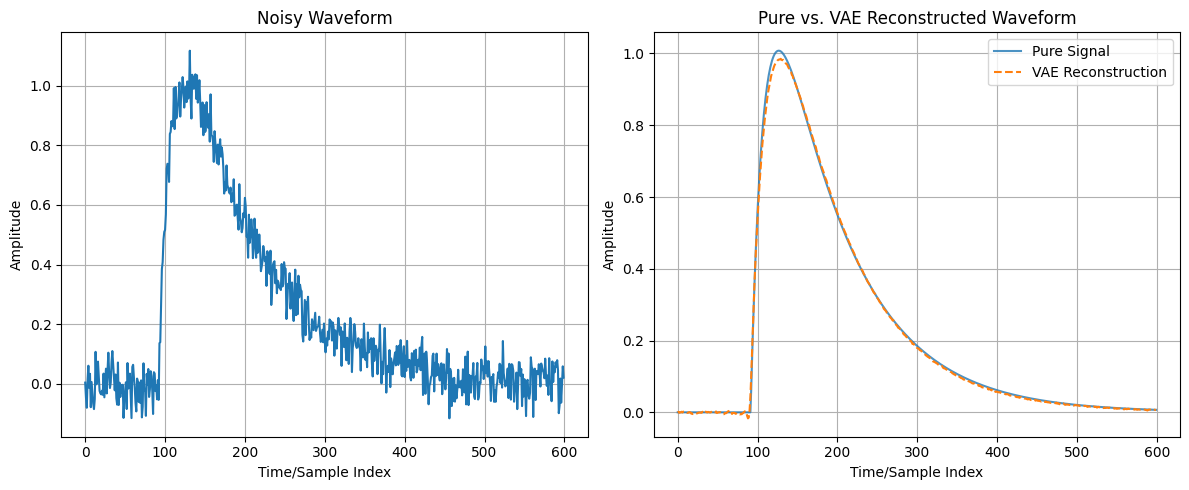

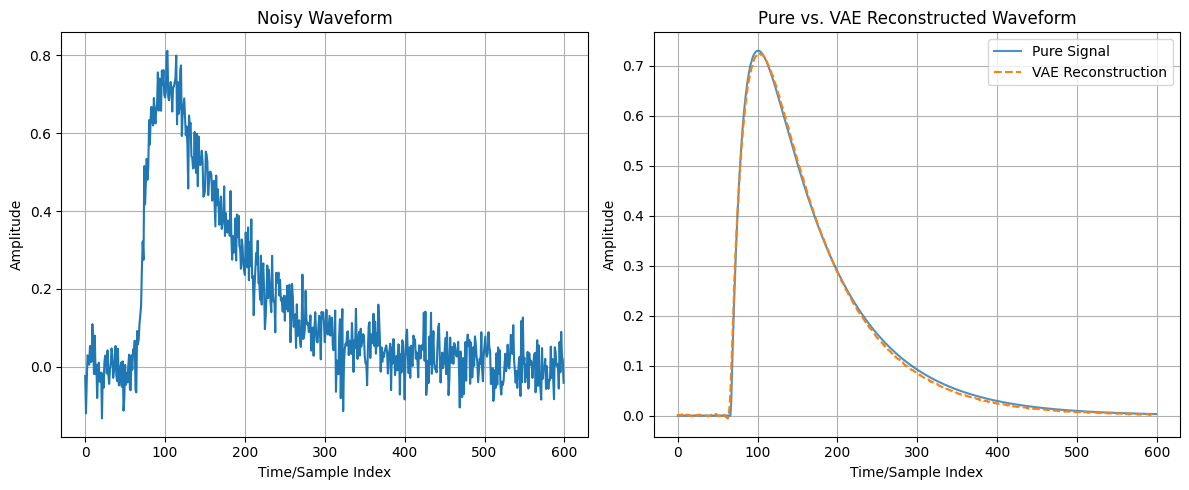

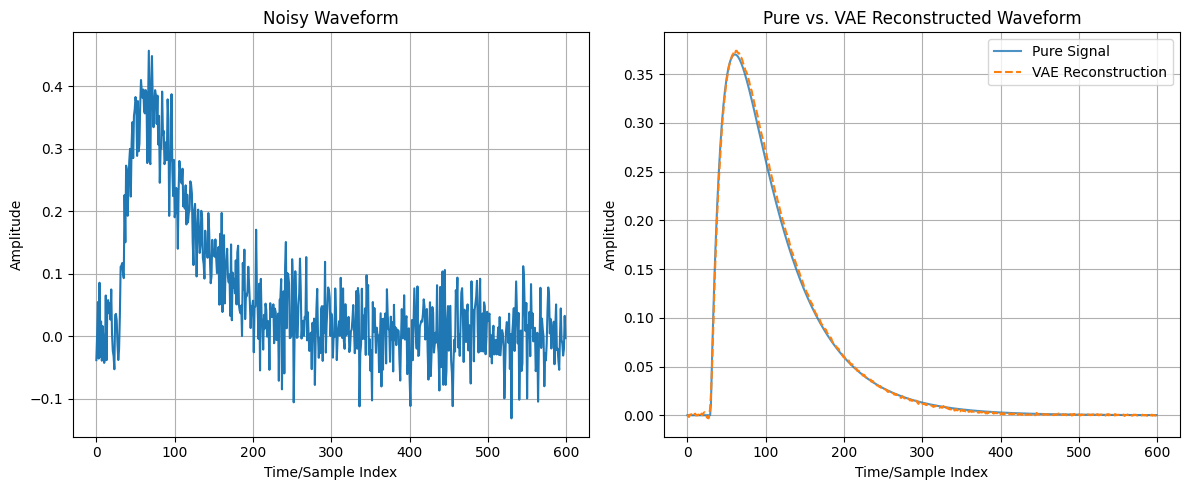

In [ ]:
# Generate reconstructions
num_reconstructions = 1000
samples = noisy_input_test[:num_reconstructions]

# The VAE's predict method returns (reconstruction, z_mean, z_log_var). We only need the reconstruction.
reconstructions, _, _ = model.predict(samples)

# Plot reconstructions
for i in np.arange(0, num_reconstructions):
    # Prediction index corresponds to the original full dataset index
    prediction_index = i + percentage_training

    # Get the sample and the reconstruction
    original = y_val_noisy[prediction_index]
    pure = y_val_pure[prediction_index]

    # Reconstructed waveform from the VAE, scaled back by the original scale factor
    reconstruction = np.array(reconstructions[i] / scale_factors[prediction_index])


    if i > 10:
      continue
    # Matplotlib preparations for plotting
    fig, axes = plt.subplots(1, 2, figsize=(12, 5)) # Adjust figure size for better readability

    # Plot noisy input sample
    axes[0].plot(original)
    axes[0].set_title('Noisy Waveform')
    axes[0].set_xlabel('Time/Sample Index')
    axes[0].set_ylabel('Amplitude')
    axes[0].grid(True)

    # Plot pure signal and reconstructed waveform for comparison
    axes[1].plot(pure, label="Pure Signal", alpha=0.8)
    axes[1].plot(reconstruction, label="VAE Reconstruction", linestyle='--')
    axes[1].set_title('Pure vs. VAE Reconstructed Waveform')
    axes[1].set_xlabel('Time/Sample Index')
    axes[1].set_ylabel('Amplitude')
    axes[1].legend(loc='best')
    axes[1].grid(True)

    plt.tight_layout() # Adjust layout to prevent labels from overlapping
    plt.show()

# Compare the fitted params of the reco shape against the original one

In [ ]:
def fitFunc(t, tauRise, tauDecay, theta, norm):
    return norm * (np.exp(-(t-theta)/tauDecay) - np.exp(-(t-theta)/tauRise))/(tauDecay - tauRise) * (t > theta) #heaviside

Text(0.5, 1.0, 't_shift')

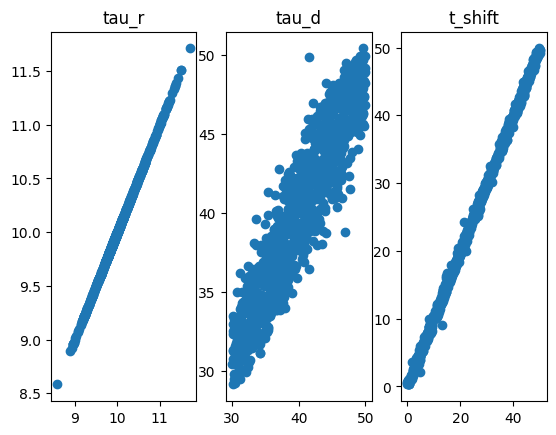

In [ ]:
from scipy.optimize import curve_fit # https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.curve_fit.html


initial_guess = np.array([10, 40, 0, 0.5])
bounds = np.array([[0,0,-100, 0],[20,80,100, 100]])

pure_pars_taur = []
pure_pars_taud = []
pure_pars_tshift = []
noisy_pars_taur = []
noisy_pars_taud = []
noisy_pars_tshift = []


for i in np.arange(0, num_reconstructions):
    # Prediction index
    prediction_index = i + percentage_training
    # Get the sample and the reconstruction
    original = y_val_noisy[prediction_index]
    pure = y_val_pure[prediction_index]
    reconstruction = np.array(reconstructions[i] / scale_factors[prediction_index])


    #fit the pure shapes
    popt,pcov = curve_fit(fitFunc, xdata=x_val_pure[prediction_index], ydata=y_val_pure[prediction_index]/np.sum(y_val_pure[prediction_index]),
             p0=initial_guess,
             sigma=None, #else None
             bounds=bounds,#(-np.inf,np.inf)
             )

    perr = (np.diag(pcov))**0.5
    #for i in range(len(popt)):
    #    print('Parametro ', i+1, ': ', popt[i], ' +/- ', perr[i])

    pure_pars_taur.append(popt[0])
    pure_pars_taud.append(popt[1])
    pure_pars_tshift.append(popt[2])


    #fit the reconstructed shapes
    popt,pcov = curve_fit(fitFunc, xdata=x_val_pure[prediction_index], ydata=reconstruction/np.sum(reconstruction),
             p0=initial_guess,
             sigma=None, #else None
             bounds=bounds,#(-np.inf,np.inf)
             )

    perr = (np.diag(pcov))**0.5
    #for i in range(len(popt)):
    #    print('Parametro ', i+1, ': ', popt[i], ' +/- ', perr[i])

    noisy_pars_taur.append(popt[0])
    noisy_pars_taud.append(popt[1])
    noisy_pars_tshift.append(popt[2])

    #x_fit = np.linspace(np.min(x_val_pure[prediction_index]),np.max(x_val_pure[prediction_index]),1000)
    #plt.plot(x_val_pure[prediction_index],reconstruction/np.sum(reconstruction),'o',color='k',label='Data')
    #plt.plot(x_val_pure[prediction_index],fitFunc(x_val_pure[prediction_index],*popt),color='r',label='Fit')


#plot parameters correlation
fig, axes = plt.subplots(1, 3)
axes[0].plot(noisy_pars_taur, noisy_pars_taur, 'o')
axes[0].set_title('tau_r')
axes[1].plot(pure_pars_taud, noisy_pars_taud, 'o')
axes[1].set_title('tau_d')
axes[2].plot(pure_pars_tshift, noisy_pars_tshift, 'o')
axes[2].set_title('t_shift')


# Visualizing the Latent Space

Now, let's visualize the 2D latent space learned by the VAE. This can provide insights into how the model organizes different types of pulse shapes.

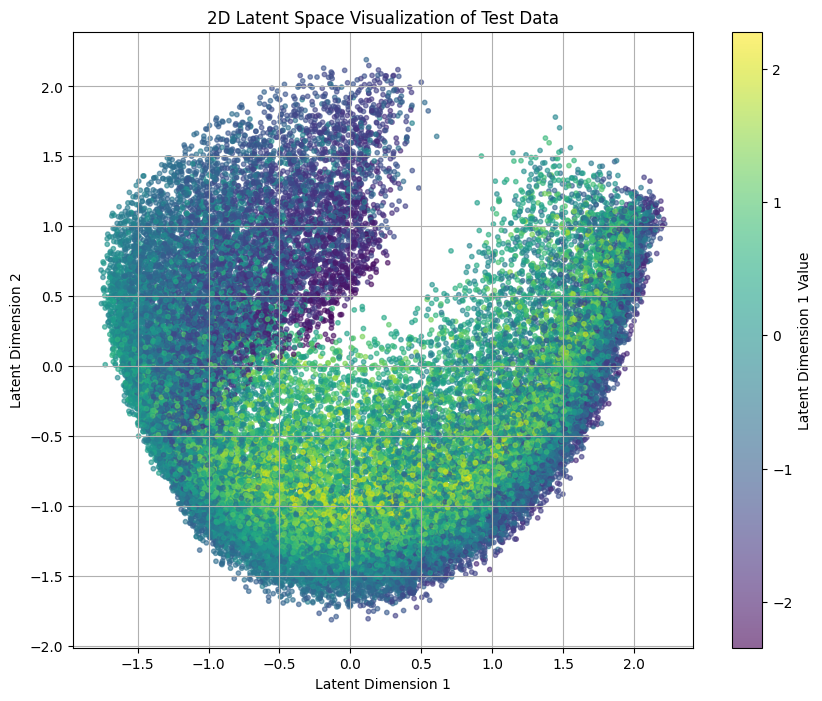

In [ ]:
from matplotlib import pyplot as plt

# Get the latent space representation (z_mean) for the test set
# We only need the encoder part of the VAE, which is implicitly used in the call method
# but we are interested in z_mean and z_log_var. The call method returns reconstruction, z_mean, z_log_var.
_, z_mean_test, _ = vae(noisy_input_test)

# Convert z_mean_test to a NumPy array for easier plotting
z_mean_test_np = z_mean_test.numpy()

plt.figure(figsize=(10, 8))
# Explicitly use the first latent dimension for coloring (c=z_mean_test_np[:, 0])
plt.scatter(z_mean_test_np[:, 2], z_mean_test_np[:, 1], c=z_mean_test_np[:, 0], cmap='viridis', s=10, alpha=0.6)
plt.colorbar(label='Latent Dimension 1 Value') # Color by one of the latent dimensions for additional insight
plt.title('2D Latent Space Visualization of Test Data')
plt.xlabel('Latent Dimension 1')
plt.ylabel('Latent Dimension 2')
plt.grid(True)
plt.show()

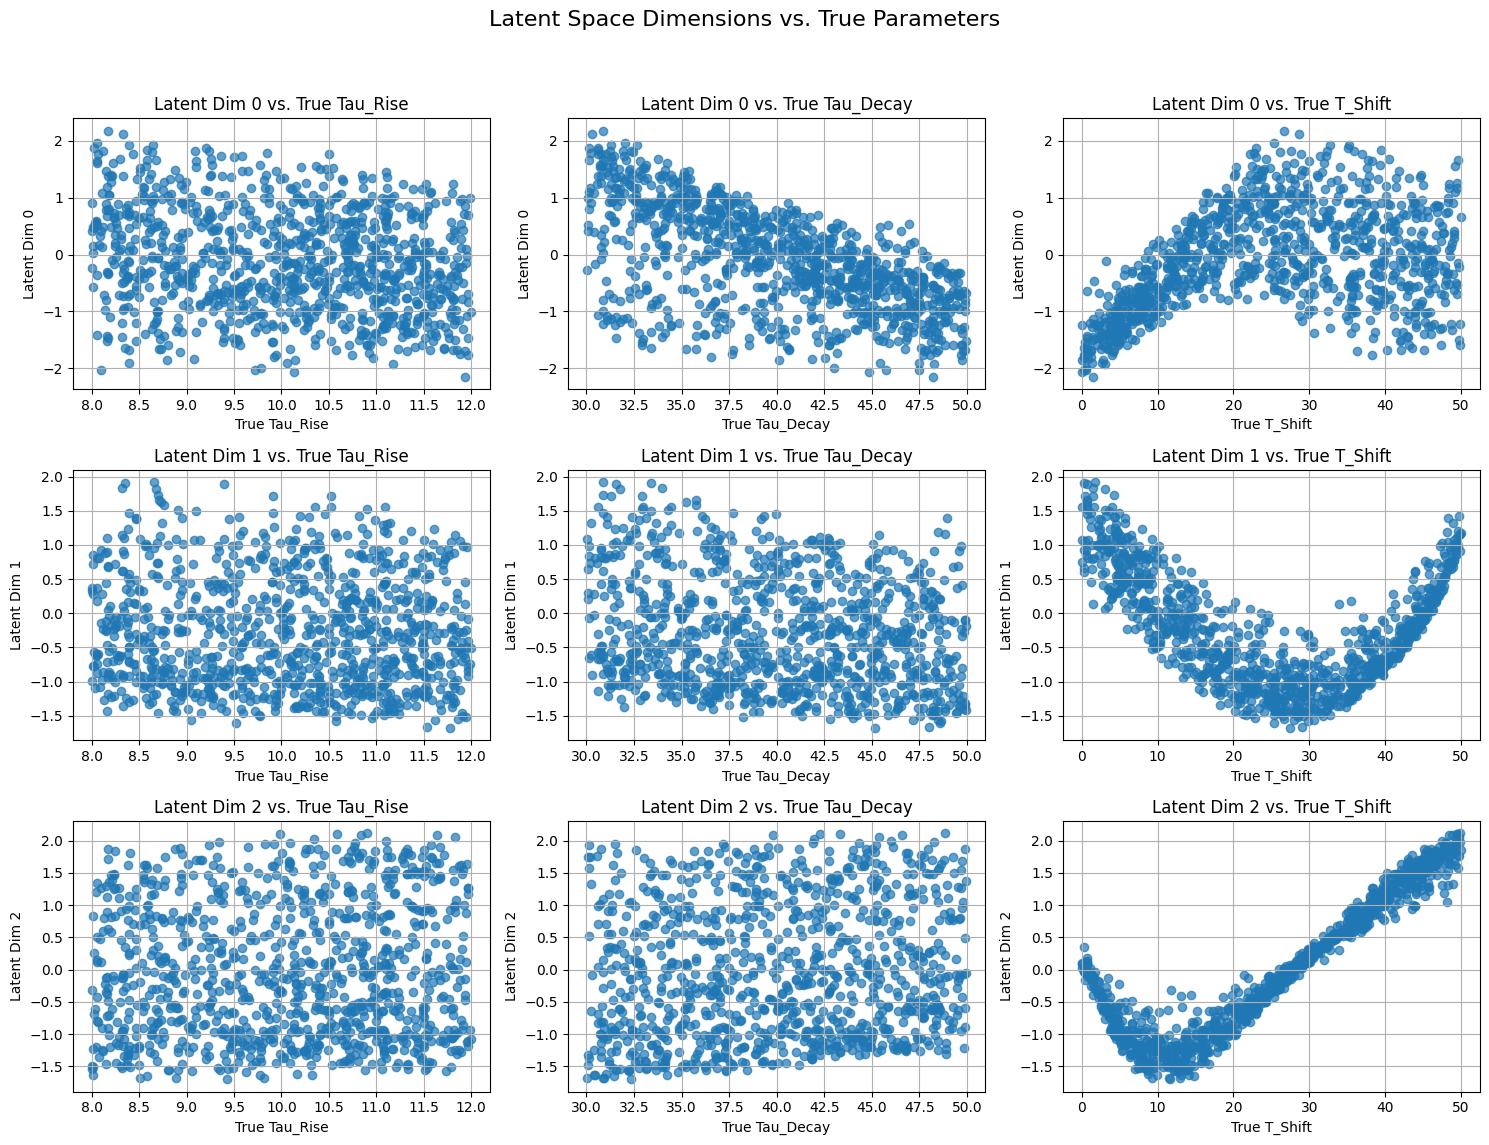

In [ ]:
from matplotlib import pyplot as plt

# Ensure z_mean_test is re-computed if the VAE model was retrained or latent_dim changed
# The latent_dim is now 3, so z_mean_test_np will have 3 columns.
_, z_mean_test, _ = vae(noisy_input_test)
z_mean_test_np = z_mean_test.numpy()

# Take only the first `num_reconstructions` samples for comparison,
# as pure_pars arrays were generated for these samples.
num_samples_to_compare = num_reconstructions # Corrected to match the size of pure_pars
z_mean_subset = z_mean_test_np[:num_samples_to_compare]

# Prepare true parameters for plotting
true_params = {
    'tau_r': pure_pars_taur,
    'tau_d': pure_pars_taud,
    't_shift': pure_pars_tshift
}
latent_dim_labels = ['Latent Dim 0', 'Latent Dim 1', 'Latent Dim 2']
param_labels = ['True Tau_Rise', 'True Tau_Decay', 'True T_Shift']

# Create a grid of scatter plots for comparison
fig, axes = plt.subplots(latent_dim, len(true_params), figsize=(15, 12))
fig.suptitle('Latent Space Dimensions vs. True Parameters', fontsize=16)

for i in range(latent_dim):
    for j, (param_name, param_values) in enumerate(true_params.items()):
        ax = axes[i, j]
        ax.scatter(param_values, z_mean_subset[:, i], alpha=0.7)
        ax.set_xlabel(param_labels[j])
        ax.set_ylabel(latent_dim_labels[i])
        ax.set_title(f'{latent_dim_labels[i]} vs. {param_labels[j]}')
        ax.grid(True)

plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to make space for suptitle
plt.show()